# Multi-objective BO on BraninCurrin: ModelListGP vs MTGP vs Random Forest

This notebook combines two things:

- The **closed-loop multi-objective BO** problem from `BOTorchTutorial-MOBO.ipynb`: the noisy
  two-objective BraninCurrin benchmark on $[0,1]^2$, optimised in batches of $q$ points, with
  progress measured by the hypervolume of the points found.
- The **three-surrogate framework** from `BO_Bioreactor_v2.ipynb`:
  - **ModelListGP**: two independent `SingleTaskGP`s, one per objective
  - **MTGP**: `MultiTaskGP` (ICM coregionalization, `rank=2`), which can learn a correlation between the objectives
  - **RandomForest**: one sklearn RF per objective, wrapped as a BoTorch `Model`. Its uncertainty is
    the variance across trees plus a known-noise floor.

In the tutorial the **acquisition function** changed (qNParEGO vs qEHVI vs qNEHVI) and the model stayed the
same. Here it is the other way round: all three surrogates use the same acquisition function,
**qLogNEHVI** (the numerically stable log version of qNEHVI), so the only thing that changes is the
**surrogate model**. A quasi-random **Sobol** baseline is included as a reference.

---
## The problem

Two coupled objectives on $x = (x_1, x_2) \in [0,1]^2$:

- **Branin**, a classic benchmark with three global minima, evaluated on inputs rescaled from the unit
  square ($\bar x_1 = 15x_1 - 5$, $\bar x_2 = 15x_2$), with $a=1$, $b=5.1/(4\pi^2)$, $c=5/\pi$, $r=6$, $s=10$, $t=1/(8\pi)$:

$$
f_1(x_1,x_2)= a(\bar x_2-b\bar x_1^2+c\bar x_1-r)^2 + s(1-t)\cos(\bar x_1) + s
$$

- **Currin**, a function with complex curvature:

$$
f_2(x_1,x_2) = \left(1-e^{-1/(2x_2)}\right)\frac{2300x_1^3 + 1900x_1^2 + 2092x_1+60}{100x_1^3+500x_1^2+4x_1+20}
$$

Each observation has additive Gaussian noise with standard deviations $15.19$ and $0.63$. BoTorch
maximises by convention, so both objectives are negated (`negate=True`).

**How this maps to the bioreactor notebook.** The noise standard deviations play the role of the
`yield_SD` / `biomass_productivity_SD` columns. The measurement noise is *known*, so it is passed
to the surrogates as `train_Yvar` exactly as before, instead of letting each model re-estimate it. Here
the noise is the same at every point (homoscedastic). In the lab data it varies from point to point
(heteroscedastic), but the code is identical: only the values in `train_Yvar` change.

In [1]:
import time
import warnings
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")        # deprecation noise from recent torch
warnings.filterwarnings("ignore", message=".*Sparse invariant checks.*")  # internal linear_operator warning
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from torch import Tensor
from sklearn.ensemble import RandomForestRegressor

# BoTorch / GPyTorch
from botorch import fit_gpytorch_mll
from botorch.test_functions.multi_objective import BraninCurrin
from botorch.models import ModelListGP, MultiTaskGP, SingleTaskGP
from botorch.models.model import Model
from botorch.posteriors import Posterior
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.sampling.get_sampler import GetSampler
from botorch.acquisition.multi_objective.logei import qLogNoisyExpectedHypervolumeImprovement
from botorch.optim.optimize import optimize_acqf, optimize_acqf_discrete
from botorch.utils.transforms import normalize, unnormalize
from botorch.utils.sampling import draw_sobol_samples
from botorch.utils.multi_objective.box_decompositions.dominated import DominatedPartitioning
from botorch.utils.multi_objective.pareto import is_non_dominated
from botorch.exceptions import BadInitialCandidatesWarning
from botorch.exceptions.warnings import NumericsWarning, OptimizationWarning
from gpytorch.kernels import IndexKernel
from gpytorch.mlls import ExactMarginalLogLikelihood, SumMarginalLogLikelihood
from linear_operator.utils.warnings import NumericalWarning

# Benign warnings that would otherwise flood the BO loop output:
# - NumericalWarning: jitter added to a near-singular covariance (sampled points cluster near the Pareto front)
# - "Optimization failed ..." / OptimizationWarning: an L-BFGS-B line search stalled on a flat acquisition
#   surface; BoTorch automatically retries from a new set of initial conditions
warnings.filterwarnings("ignore", category=NumericsWarning)
warnings.filterwarnings("ignore", category=BadInitialCandidatesWarning)
warnings.filterwarnings("ignore", category=NumericalWarning)
warnings.filterwarnings("ignore", category=OptimizationWarning)
warnings.filterwarnings("ignore", message="Optimization failed", category=RuntimeWarning)

RSEED = 42
tkwargs = {"dtype": torch.double, "device": torch.device("cuda" if torch.cuda.is_available() else "cpu")}

## 1. Problem set up

In [2]:
problem = BraninCurrin(negate=True).to(**tkwargs)
NOISE_SE = torch.tensor([15.19, 0.63], **tkwargs)   # known measurement noise (SD), one per objective

objective_names = ["Branin (negated)", "Currin (negated)"]

print(f"Input dimension: d = {problem.dim}, bounds = {problem.bounds.T.tolist()}")
print(f"Reference point: {problem.ref_point.tolist()}")
print(f"Max hypervolume (true Pareto front): {problem.max_hv:.4f}")

Input dimension: d = 2, bounds = [[0.0, 1.0], [0.0, 1.0]]
Reference point: [-18.0, -6.0]
Max hypervolume (true Pareto front): 59.3601


BraninCurrin is a synthetic function, so (unlike the experimental dataset) the noise-free objectives can
be evaluated anywhere. A dense grid gives a good approximation of the **true Pareto front** (in
objective space) and of the **Pareto set** (the inputs that produce it). Both are used only as a
reference in the plots below and are never shown to the optimiser.

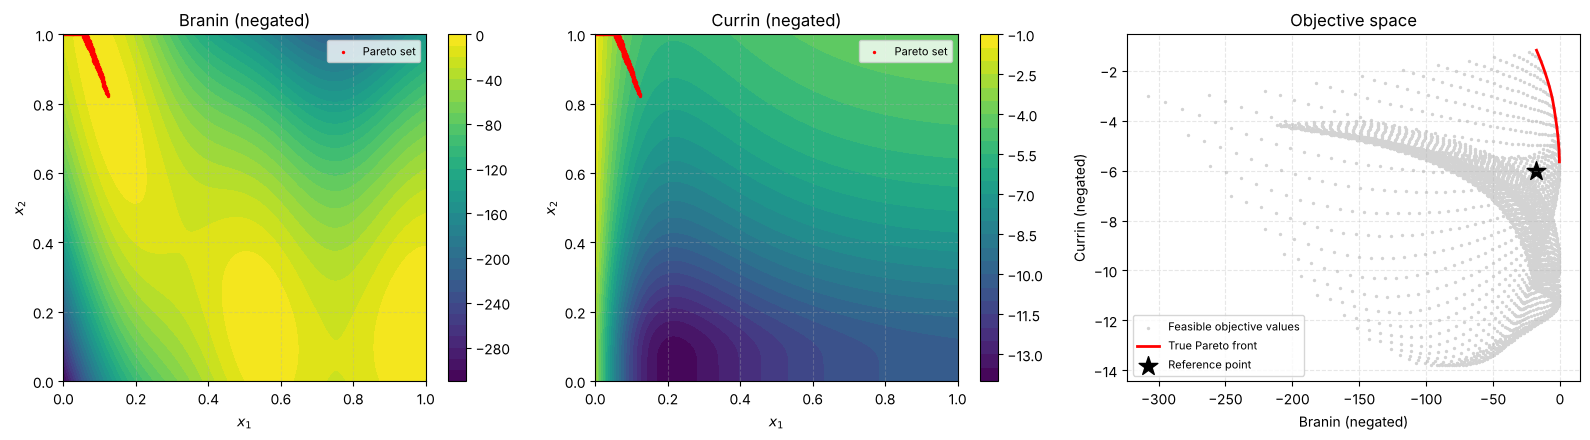

In [3]:
# --------------------------------------------------------------------
# Dense grid of noise-free evaluations (for plotting only)
# --------------------------------------------------------------------
n_grid = 400
g = torch.linspace(0, 1, n_grid, **tkwargs)
X_grid = unnormalize(torch.stack(torch.meshgrid(g, g, indexing="ij"), dim=-1).reshape(-1, 2), problem.bounds)
Y_grid = problem(X_grid)

# Branin has three global minima with the same value, so on a finite grid a point next to the
# "wrong" minimum can win the tie by ~1e-3 and show up as a spurious isolated Pareto point.
# Rounding to 3 decimals before the non-dominance check removes that discretisation artefact.
grid_pareto_mask = is_non_dominated(torch.round(Y_grid, decimals=3))
order = torch.argsort(Y_grid[grid_pareto_mask][:, 0])
true_pareto_X = X_grid[grid_pareto_mask][order].cpu().numpy()
true_pareto_Y = Y_grid[grid_pareto_mask][order].cpu().numpy()

# --------------------------------------------------------------------
# Visualise the objectives, the Pareto set and the Pareto front
# --------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x1 = X_grid[:, 0].reshape(n_grid, n_grid).cpu().numpy()
x2 = X_grid[:, 1].reshape(n_grid, n_grid).cpu().numpy()
for i in range(2):
    cs = axes[i].contourf(x1, x2, Y_grid[:, i].reshape(n_grid, n_grid).cpu().numpy(), levels=30, cmap="viridis")
    fig.colorbar(cs, ax=axes[i])
    axes[i].scatter(true_pareto_X[:, 0], true_pareto_X[:, 1], s=2, c="red", label="Pareto set")
    axes[i].set(xlabel="$x_1$", ylabel="$x_2$", title=objective_names[i])
    axes[i].legend(loc="upper right", fontsize=8)

sub = slice(None, None, 37)   # subsample the grid so the scatter stays light
axes[2].scatter(Y_grid[sub, 0].cpu().numpy(), Y_grid[sub, 1].cpu().numpy(), s=2, c="lightgrey", label="Feasible objective values")
axes[2].plot(true_pareto_Y[:, 0], true_pareto_Y[:, 1], c="red", linewidth=2, label="True Pareto front")
axes[2].scatter(*problem.ref_point.cpu().numpy(), marker="*", s=200, c="black", label="Reference point")
axes[2].set(xlabel=objective_names[0], ylabel=objective_names[1], title="Objective space")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.grid(True, alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

## 2. Data generation, normalisation & known noise

`generate_initial_data` and `observe` stand in for running the experiment: they return the noisy
observation (what the optimiser sees) and the noise-free value (used only to compute the hypervolume).

`prepare_training_data` applies the same pre-processing as `BO_Bioreactor_v2.ipynb`:

1. Inputs are normalised to $[0,1]^d$ (BraninCurrin is already defined on $[0,1]^2$, but the step is
   kept so the code carries over to any bounds).
2. Each output is **standardised** separately (zero mean, unit variance). This matters for the MTGP,
   whose stacked layout puts both outputs in a single column; without per-output scaling, the Branin
   values (range ~300) would swamp the Currin values (range ~12).
3. The known noise is passed as a **variance** and rescaled the same way:
   `train_Yvar_scaled = (SD / Y_std)**2`.
4. The reference point is moved into the same standardised space: `(ref_point - Y_mean) / Y_std`.

In a closed loop the dataset grows every iteration, so `Y_mean`/`Y_std` are **recomputed every
iteration**. This does not change which candidates get picked. Standardising is a positive affine map
applied to each objective, so every hypervolume (and every hypervolume improvement) is multiplied by
the same constant $1/(\sigma_1\sigma_2)$, and the argmax of the acquisition function stays where it was.

In [4]:
def observe(new_x):
    '''Runs the "experiment": returns the noisy observation and the noise-free value.'''
    new_obj_true = problem(new_x)
    new_obj = new_obj_true + torch.randn_like(new_obj_true) * NOISE_SE
    return new_obj, new_obj_true


def generate_initial_data(n=6):
    '''Draws n Sobol points in the search space and observes them.'''
    train_x = draw_sobol_samples(bounds=problem.bounds, n=n, q=1).squeeze(1)
    train_obj, train_obj_true = observe(train_x)
    return train_x, train_obj, train_obj_true


def prepare_training_data(train_x, train_obj):
    '''
    Normalises inputs to [0, 1]^d, standardises each output, and propagates the same
    scaling to the known noise variances and to the reference point.
    '''
    train_X = normalize(train_x, problem.bounds)

    Y_mean = train_obj.mean(dim=0)
    Y_std  = train_obj.std(dim=0)
    train_Y_scaled    = (train_obj - Y_mean) / Y_std
    train_Yvar_scaled = (NOISE_SE ** 2).expand_as(train_obj) / Y_std ** 2   # variance rescales by std**2, no mean shift
    ref_point_scaled  = (problem.ref_point - Y_mean) / Y_std
    return train_X, train_Y_scaled, train_Yvar_scaled, ref_point_scaled, Y_mean, Y_std

## 3. The three surrogate models

### 3.1 Model A — ModelListGP (independent GPs, with known noise)

Two separate `SingleTaskGP`s, one per objective, batched together by `ModelListGP`. Passing
`train_Yvar` replaces the default `GaussianLikelihood` (one learned noise level) with a
`FixedNoiseGaussianLikelihood` that pins the noise at each point to the known variance. This is the same
setup as the tutorial, which also builds a `ModelListGP` of `SingleTaskGP`s with known noise.

In [5]:
def build_model_list_gp(train_X, train_Y, train_Yvar=None):
    '''Two independent SingleTaskGPs, one per output, with optional known (fixed) noise.'''
    models = []
    for i in range(train_Y.shape[1]):
        yvar_i = None if train_Yvar is None else train_Yvar[:, i:i + 1]
        gp = SingleTaskGP(train_X=train_X, train_Y=train_Y[:, i:i + 1], train_Yvar=yvar_i)
        models.append(gp)
    return ModelListGP(*models)

### 3.2 Model B — MultiTaskGP (correlated MTGP, with known noise)

`MultiTaskGP` uses ICM coregionalization. The joint covariance factorises into a kernel over the
inputs times a learned $2\times2$ task covariance $K_f$ over the outputs. The data are "stacked":
every point appears once per output, with an extra task-index column, and per-point `train_Yvar` is
supported.

As in the bioreactor notebook, `rank=2` (full rank for two outputs) is used. A rank-1 factorisation of
a $2\times2$ covariance forces the task correlation to be exactly $\pm1$, whatever the data say.

**One change from the bioreactor notebook: the task kernel.** Recent BoTorch versions (e.g. 0.18) build
`MultiTaskGP` with a `PositiveIndexKernel`: every entry of $K_f$ is constrained to be **non-negative**,
and a `Beta(2.5, 1.5)` prior pushes the correlation towards positive values. Even with `rank=2`, the
correlation is therefore *not* free to be estimated: it can only lie in $[0, 1]$. For BraninCurrin
this matters, because the two (negated) objectives are **negatively** correlated (about $-0.46$
over the domain; this is the trade-off that creates the Pareto front). `build_mtgp` therefore replaces
the task kernel with a plain gpytorch `IndexKernel`
($K_f = BB^\top + \mathrm{diag}(v)$, no sign constraint, no prior) by default. Set
`positive_task_corr=True` to keep the BoTorch default. Section 6.5 compares what the two kernels learn.

In [6]:
def build_mtgp(train_X, train_Y, train_Yvar=None, rank=2, positive_task_corr=False):
    '''
    MultiTaskGP with ICM coregionalization, stacked ("long") data layout.
    Every training point is duplicated once per output, with an extra task-index
    column appended to X. rank controls the expressivity of the task covariance.
    positive_task_corr=False swaps BoTorch's PositiveIndexKernel for an unconstrained
    IndexKernel, so negative correlations between outputs can be learned.
    '''
    n, d = train_X.shape
    m = train_Y.shape[1]

    X_stack = train_X.repeat(m, 1)
    task_idx = torch.cat([torch.full((n, 1), i, dtype=train_X.dtype, device=train_X.device) for i in range(m)], dim=0)
    X_aug = torch.cat([X_stack, task_idx], dim=-1)   # (n*m, d+1), task index is the last column

    Y_stack = torch.cat([train_Y[:, i:i + 1] for i in range(m)], dim=0)          # (n*m, 1)
    Yvar_stack = None
    if train_Yvar is not None:
        Yvar_stack = torch.cat([train_Yvar[:, i:i + 1] for i in range(m)], dim=0)  # (n*m, 1)

    model = MultiTaskGP(
        train_X=X_aug, train_Y=Y_stack, train_Yvar=Yvar_stack,
        task_feature=-1, output_tasks=list(range(m)), rank=rank,
    )
    if not positive_task_corr:
        # covar_module = data kernel * task kernel; keep the data kernel, replace the task kernel
        data_kernel, task_kernel = model.covar_module.kernels
        model.covar_module = data_kernel * IndexKernel(num_tasks=m, rank=rank, active_dims=task_kernel.active_dims)
    return model

### 3.3 Model C — Random Forest with bootstrap uncertainty + known noise

This is the same model as in `BO_Bioreactor_v2.ipynb`: one `RandomForestRegressor` per output, with
**inverse-variance sample weights** at fit time and a **known-noise floor** added to the tree variance
at prediction time. The variance across trees is *not* a Bayesian posterior; it is a bootstrap proxy
for model disagreement.

Running the RF inside a BoTorch acquisition function in a closed loop required three changes to the
wrapper:

1. **`base_sample_shape` / `batch_range` fix.** BoTorch evaluates the acquisition function on many
   candidates at once: the posterior mean has shape `(batch, q, m)`, e.g. `(2048, 1, 2)`. The
   original `RFPosterior` reported `base_sample_shape = (q, m)` and `batch_range = (0, 0)`, so the
   sampler drew base samples of shape `(MC, q, m)` = `(128, 1, 2)`. Those cannot be broadcast against
   a `(2048, 1, 2)` mean, and the evaluation fails with
   `RuntimeError: The size of tensor a (128) must match the size of tensor b (2048)`. The fix follows
   `GPyTorchPosterior`: `base_sample_shape` is the **full** mean shape, and `batch_range = (0, -2)`
   marks the leading dimensions as batch dimensions. The sampler then collapses those to size 1, so
   every candidate is scored with the *same* base samples (common random numbers), which is what
   makes candidates comparable to each other.
2. **Registered sampler.** qNEHVI prunes the baseline with `get_sampler(posterior)`, which needs to
   know which sampler goes with an `RFPosterior`. A one-line `GetSampler.register` maps it to the same
   `SobolQMCNormalSampler` the GPs use.
3. **Predict on unique rows only.** qNEHVI evaluates the model *jointly* on `[X_baseline, X]` for
   every candidate, so the same baseline rows are sent to the forest thousands of times. Predicting
   once per unique row and scattering the results back gives identical numbers and is much faster.

In [7]:
class RFPosterior(Posterior):
    '''
    Minimal BoTorch-compatible posterior backed by RF tree-variance.

    _mean:     (*batch, q, m)
    _variance: (*batch, q, m)  — diagonal only, independent per output and per point
    '''
    def __init__(self, mean: Tensor, variance: Tensor):
        super().__init__()
        self._mean = mean
        self._variance = variance

    @property
    def device(self) -> torch.device:
        return self._mean.device

    @property
    def dtype(self) -> torch.dtype:
        return self._mean.dtype

    @property
    def mean(self) -> Tensor:
        return self._mean

    @property
    def variance(self) -> Tensor:
        return self._variance

    @property
    def base_sample_shape(self) -> torch.Size:
        # Full shape (*batch, q, m), the same convention as GPyTorchPosterior
        return self._mean.shape

    @property
    def batch_range(self) -> tuple[int, int]:
        # Every dim except the last two (q, m) is a t-batch dim; the sampler collapses
        # these to size 1 so all candidates share the same base samples
        return (0, -2)

    @property
    def batch_shape(self) -> torch.Size:
        return self._mean.shape[:-2]

    def _extended_shape(self, sample_shape: torch.Size = torch.Size()) -> torch.Size:
        return sample_shape + self._mean.shape

    def rsample_from_base_samples(self, sample_shape: torch.Size, base_samples: Tensor) -> Tensor:
        '''base_samples: (*sample_shape, *batch, q, m), broadcasts against mean/std (*batch, q, m).'''
        std = self._variance.clamp(min=1e-9).sqrt()
        return self._mean + base_samples * std

    def rsample(self, sample_shape: torch.Size = torch.Size()) -> Tensor:
        '''Reparameterised samples mu + eps * sigma, eps ~ N(0, 1). Shape (*sample_shape, *batch, q, m).'''
        std = self._variance.clamp(min=1e-9).sqrt()
        eps = torch.randn(*sample_shape, *self._mean.shape, dtype=self._mean.dtype, device=self._mean.device)
        return self._mean + eps * std


@GetSampler.register(RFPosterior)
def _get_sampler_rf(posterior, sample_shape, *, seed=None):
    '''Lets BoTorch utilities (e.g. qNEHVI baseline pruning) build a sampler for RFPosterior.'''
    return SobolQMCNormalSampler(sample_shape=sample_shape, seed=seed)


class RandomForestModel(Model):
    '''
    BoTorch Model wrapper around one sklearn RandomForestRegressor per output.
    Uncertainty = tree-ensemble variance (epistemic) + known-noise floor (aleatoric).
    '''
    def __init__(self, train_X: Tensor, train_Y: Tensor, train_Yvar: Tensor = None, **rf_kwargs):
        super().__init__()
        self._num_outputs = train_Y.shape[-1]
        X_np = train_X.detach().cpu().numpy()
        Y_np = train_Y.detach().cpu().numpy()

        self.rfs = []
        self._noise_floor = np.zeros(self._num_outputs)
        for i in range(self._num_outputs):
            rf = RandomForestRegressor(
                n_estimators=rf_kwargs.get('n_estimators', 500),
                max_depth=rf_kwargs.get('max_depth', None),
                random_state=RSEED,
            )
            sample_weight = None
            if train_Yvar is not None:
                var_i = train_Yvar[:, i].detach().cpu().numpy()
                sample_weight = 1.0 / np.clip(var_i, 1e-8, None)      # inverse-variance weighting
                sample_weight = sample_weight / sample_weight.mean()   # normalise for stability
                self._noise_floor[i] = var_i.mean()                    # aleatoric floor for unseen X
            rf.fit(X_np, Y_np[:, i], sample_weight=sample_weight)
            self.rfs.append(rf)

        self._dtype = train_X.dtype
        self._device = train_X.device

    @property
    def num_outputs(self) -> int:
        return self._num_outputs

    def posterior(self, X: Tensor, **kwargs) -> RFPosterior:
        '''
        Compute tree-ensemble mean/variance + noise floor.
        X shape: (..., q, d)  — arbitrary batch dimensions + q candidates
        Returns posterior with mean/variance shape (..., q, m).
        '''
        batch_shape = X.shape[:-2]
        q, d = X.shape[-2], X.shape[-1]
        X_flat = X.reshape(-1, d).detach().cpu().numpy()  # (batch*q, d)

        # qNEHVI evaluates [X_baseline, X] jointly for every candidate, so the same rows
        # repeat many times: predict once per unique row and scatter back
        X_unique, inverse = np.unique(X_flat, axis=0, return_inverse=True)
        inverse = inverse.reshape(-1)

        means, varis = [], []
        for i, rf in enumerate(self.rfs):
            tree_preds = np.stack([tree.predict(X_unique) for tree in rf.estimators_], axis=0)  # (n_trees, n_unique)
            means.append(tree_preds.mean(axis=0)[inverse])
            varis.append(tree_preds.var(axis=0)[inverse] + self._noise_floor[i])
        mean_np = np.stack(means, axis=-1)   # (batch*q, m)
        var_np  = np.stack(varis, axis=-1)   # (batch*q, m)

        m = self._num_outputs
        mean = torch.tensor(mean_np, dtype=self._dtype, device=self._device).reshape(*batch_shape, q, m)
        var  = torch.tensor(var_np,  dtype=self._dtype, device=self._device).reshape(*batch_shape, q, m)
        return RFPosterior(mean, var)

### 3.4 One entry point for all three models

`initialize_and_fit_model` builds a surrogate from the (scaled) training data and fits it: the two GPs by
maximising the marginal log-likelihood, the RF when it is constructed.

In [8]:
MODEL_NAMES = ["ModelListGP", "MTGP", "RF"]


def initialize_and_fit_model(model_name, train_X, train_Y, train_Yvar):
    '''Builds and fits one of the three surrogates on standardised data with known noise.'''
    if model_name == "ModelListGP":
        model = build_model_list_gp(train_X, train_Y, train_Yvar)
        fit_gpytorch_mll(SumMarginalLogLikelihood(model.likelihood, model))
    elif model_name == "MTGP":
        model = build_mtgp(train_X, train_Y, train_Yvar, rank=2)
        fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood, model))
    elif model_name == "RF":
        model = RandomForestModel(train_X, train_Y, train_Yvar, n_estimators=500)
    else:
        raise ValueError(f"Unknown model: {model_name}")
    return model


# --------------------------------------------------------------------
# Sanity check: all three models on a small initial design
# --------------------------------------------------------------------
torch.manual_seed(RSEED)
_x, _obj, _ = generate_initial_data(n=2 * (problem.dim + 1))
_X, _Y, _Yvar, _, _, _ = prepare_training_data(_x, _obj)
for name in MODEL_NAMES:
    _model = initialize_and_fit_model(name, _X, _Y, _Yvar)
    with torch.no_grad():
        _post = _model.posterior(_X.unsqueeze(0))   # batched input (1, n, d)
    print(f"{name:<12} posterior mean shape: {tuple(_post.mean.shape)}")   # expect (1, n, 2)

ModelListGP  posterior mean shape: (1, 6, 2)
MTGP         posterior mean shape: (1, 6, 2)


RF           posterior mean shape: (1, 6, 2)


## 4. BO step: qLogNEHVI for all three models

The helper builds qLogNEHVI on the fitted surrogate, optimises it to get a batch
$x_1, \dots, x_q$, and observes the objectives at those points.

**Reference point.** BoTorch's built-in reference point for BraninCurrin, $(-18, -6)$ in the negated
objectives, is used. It is a *static, domain-knowledge* reference point: it plays the same role as
`ref_point = (0, 0)` in the bioreactor notebook (the worst outcome that is still of interest). It is
standardised with the same `Y_mean`/`Y_std` as the outputs.

**Optimising the acquisition function.** The GP posterior mean and variance are smooth in $x$, so
qLogNEHVI is optimised with multi-start L-BFGS-B (`optimize_acqf`). The batch is built in sequential
greedy fashion (`sequential=True`), as in the tutorial. An RF prediction, however, is **piecewise
constant** in $x$: its gradient is zero almost everywhere, and the wrapper goes through numpy, so
there is no autograd graph at all. Gradient-based optimisation is meaningless for it. The RF therefore
uses the same acquisition function with a **gradient-free** optimiser: qLogNEHVI is evaluated on a
fresh set of `N_RF_CANDIDATES` Sobol points each iteration, and the batch is picked greedily, each new
point conditioned on the ones already chosen (`optimize_acqf_discrete`). In 2D, 2048 Sobol points
cover the unit square at a spacing of about $0.02$.

In [9]:
BATCH_SIZE = 4           # q: experiments per BO iteration
NUM_RESTARTS = 10        # random restarts for the gradient-based acq optimisation (GPs)
RAW_SAMPLES = 512        # raw samples used to seed those restarts
MC_SAMPLES = 128         # QMC samples for the qLogNEHVI integral
N_RF_CANDIDATES = 2048   # Sobol candidate set for the gradient-free acq optimisation (RF)

standard_bounds = torch.zeros(2, problem.dim, **tkwargs)
standard_bounds[1] = 1


def optimize_qlognehvi_and_get_observation(model, train_X, ref_point_scaled):
    '''Optimises qLogNEHVI on the given surrogate and returns the new batch and its observations.'''
    sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))
    acq_func = qLogNoisyExpectedHypervolumeImprovement(
        model=model,
        ref_point=ref_point_scaled,
        X_baseline=train_X,
        prune_baseline=True,   # drop baseline points with ~zero probability of being Pareto optimal
        sampler=sampler,
    )

    # --------------------------------------------------------------------
    # Optimise: gradient-free over a Sobol candidate set for the RF, L-BFGS-B for the GPs
    # --------------------------------------------------------------------
    if isinstance(model, RandomForestModel):
        choices = draw_sobol_samples(bounds=standard_bounds, n=N_RF_CANDIDATES, q=1).squeeze(1)
        candidates, _ = optimize_acqf_discrete(acq_function=acq_func, q=BATCH_SIZE, choices=choices)
    else:
        candidates, _ = optimize_acqf(
            acq_function=acq_func,
            bounds=standard_bounds,
            q=BATCH_SIZE,
            num_restarts=NUM_RESTARTS,
            raw_samples=RAW_SAMPLES,
            options={"batch_limit": 5, "maxiter": 200},
            sequential=True,
        )

    # --------------------------------------------------------------------
    # Observe new values
    # --------------------------------------------------------------------
    new_x = unnormalize(candidates.detach(), bounds=problem.bounds)
    new_obj, new_obj_true = observe(new_x)
    return new_x, new_obj, new_obj_true

## 5. Closed BO loop

Each BO iteration, for each method:

1. Standardise the data collected so far (`prepare_training_data`).
2. Fit the surrogate (`initialize_and_fit_model`).
3. Pick a batch of $q$ points with qLogNEHVI and observe them.
4. Compute the hypervolume of the **noise-free** objective values at every point evaluated so far,
   against the reference point. The optimiser only ever sees the noisy values. The noise-free ones
   are used only to score progress.

All methods start from the same $2(d+1) = 6$ Sobol points. The Sobol baseline simply draws $q$ new
quasi-random points per iteration.

A single run of a noisy BO loop is itself noisy: one lucky batch can put a weaker method ahead. The
loop is therefore repeated for `N_TRIALS` independent trials (different initial designs and
noise draws), and the plots show the mean ± one standard error.

**Runtime.** One trial (30 iterations × 3 surrogates) took about 22 minutes on a 4-core CPU, so the
full 5-trial run takes just under 2 hours. Most of that time goes to optimising the GP acquisition
functions, which gets slower as the dataset grows. Set `N_TRIALS = 1` for a quick look, or run on a GPU.

In [10]:
N_TRIALS = 5
N_BATCH = 30
N_INIT = 2 * (problem.dim + 1)
METHODS = ["Sobol"] + MODEL_NAMES
PRINT_EVERY = 5


def compute_hv(train_obj_true):
    '''Hypervolume dominated by the noise-free objective values, w.r.t. the reference point.'''
    bd = DominatedPartitioning(ref_point=problem.ref_point, Y=train_obj_true)
    return bd.compute_hypervolume().item()


def run_trial(trial, seed):
    '''Runs N_BATCH BO iterations for every method from a shared initial design.'''
    torch.manual_seed(seed)
    np.random.seed(seed)

    # --------------------------------------------------------------------
    # Shared initial design and initial hypervolume
    # --------------------------------------------------------------------
    init_x, init_obj, init_obj_true = generate_initial_data(n=N_INIT)
    data = {m: {"x": init_x, "obj": init_obj, "obj_true": init_obj_true} for m in METHODS}
    hvs = {m: [compute_hv(init_obj_true)] for m in METHODS}
    times = {m: [] for m in MODEL_NAMES}

    for iteration in range(1, N_BATCH + 1):
        for m in METHODS:
            t0 = time.monotonic()
            if m == "Sobol":
                new_x, new_obj, new_obj_true = generate_initial_data(n=BATCH_SIZE)
            else:
                # Standardise -> fit surrogate -> optimise qLogNEHVI -> observe
                train_X, train_Y, train_Yvar, ref_point_scaled, _, _ = prepare_training_data(data[m]["x"], data[m]["obj"])
                model = initialize_and_fit_model(m, train_X, train_Y, train_Yvar)
                new_x, new_obj, new_obj_true = optimize_qlognehvi_and_get_observation(model, train_X, ref_point_scaled)
                times[m].append(time.monotonic() - t0)

            # Update training points and progress
            data[m]["x"] = torch.cat([data[m]["x"], new_x])
            data[m]["obj"] = torch.cat([data[m]["obj"], new_obj])
            data[m]["obj_true"] = torch.cat([data[m]["obj_true"], new_obj_true])
            hvs[m].append(compute_hv(data[m]["obj_true"]))

        if iteration % PRINT_EVERY == 0 or iteration == 1:
            hv_str = ", ".join(f"{hvs[m][-1]:>5.2f}" for m in METHODS)
            t_str = ", ".join(f"{times[m][-1]:>4.1f}" for m in MODEL_NAMES)
            print(f"Trial {trial} | Batch {iteration:>2}: HV ({', '.join(METHODS)}) = ({hv_str}) | time [s] ({', '.join(MODEL_NAMES)}) = ({t_str})")

    return {"data": data, "hvs": hvs, "times": times}


results = []
t_start = time.monotonic()
for trial in range(1, N_TRIALS + 1):
    results.append(run_trial(trial, seed=RSEED + trial))
    print(f"--- trial {trial} done, elapsed {time.monotonic() - t_start:.0f} s ---")

Trial 1 | Batch  1: HV (Sobol, ModelListGP, MTGP, RF) = ( 0.00, 11.38,  8.31,  1.03) | time [s] (ModelListGP, MTGP, RF) = ( 4.3,  4.3,  2.6)


Trial 1 | Batch  5: HV (Sobol, ModelListGP, MTGP, RF) = (18.44, 49.81, 43.68, 39.45) | time [s] (ModelListGP, MTGP, RF) = ( 9.5, 17.6,  3.4)


Trial 1 | Batch 10: HV (Sobol, ModelListGP, MTGP, RF) = (18.44, 54.83, 52.77, 43.04) | time [s] (ModelListGP, MTGP, RF) = (17.4, 21.9,  4.8)


Trial 1 | Batch 15: HV (Sobol, ModelListGP, MTGP, RF) = (18.44, 56.83, 57.12, 44.09) | time [s] (ModelListGP, MTGP, RF) = (13.4, 21.1,  4.9)


Trial 1 | Batch 20: HV (Sobol, ModelListGP, MTGP, RF) = (18.44, 57.10, 57.97, 44.23) | time [s] (ModelListGP, MTGP, RF) = (14.0, 22.5,  5.3)


...

Trial 5 | Batch 10: HV (Sobol, ModelListGP, MTGP, RF) = (17.18, 54.28, 56.36, 26.62) | time [s] (ModelListGP, MTGP, RF) = (24.7, 14.8,  4.5)


Trial 5 | Batch 15: HV (Sobol, ModelListGP, MTGP, RF) = (17.18, 55.38, 57.73, 49.85) | time [s] (ModelListGP, MTGP, RF) = (14.3, 13.2,  4.8)


Trial 5 | Batch 20: HV (Sobol, ModelListGP, MTGP, RF) = (19.20, 56.66, 57.97, 50.49) | time [s] (ModelListGP, MTGP, RF) = (24.6, 18.3,  5.2)


Trial 5 | Batch 25: HV (Sobol, ModelListGP, MTGP, RF) = (19.20, 57.03, 58.16, 51.91) | time [s] (ModelListGP, MTGP, RF) = (32.4, 27.9,  5.4)


Trial 5 | Batch 30: HV (Sobol, ModelListGP, MTGP, RF) = (19.20, 57.83, 58.37, 54.94) | time [s] (ModelListGP, MTGP, RF) = (26.4, 23.0,  6.2)
--- trial 5 done, elapsed 6576 s ---


## 6. Results

### 6.1 Log hypervolume difference

The tutorial's metric: the log distance between the hypervolume $H^*$ of the true Pareto front
(`problem.max_hv`) and the hypervolume $H(\tau)$ of the points found after $\tau$ observations:

$$
\mathrm{LHD}(\tau) = \log_{10}\big(H^* - H(\tau)\big)
$$

Lower is better. The curves show the mean over trials, and the shaded bands show ± one standard error.

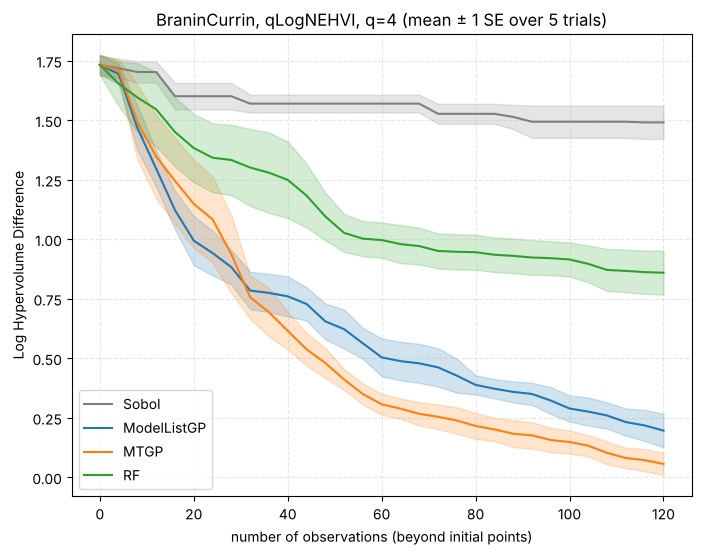

In [11]:
colors = {"Sobol": "tab:grey", "ModelListGP": "tab:blue", "MTGP": "tab:orange", "RF": "tab:green"}
iters = np.arange(N_BATCH + 1) * BATCH_SIZE

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
for m in METHODS:
    hv = np.array([r["hvs"][m] for r in results])          # (N_TRIALS, N_BATCH + 1)
    lhd = np.log10(problem.max_hv - hv)
    mean = lhd.mean(axis=0)
    se = lhd.std(axis=0, ddof=1) / np.sqrt(N_TRIALS) if N_TRIALS > 1 else np.zeros_like(mean)
    ax.plot(iters, mean, label=m, color=colors[m], linewidth=1.5)
    ax.fill_between(iters, mean - se, mean + se, color=colors[m], alpha=0.2)
ax.set(xlabel="number of observations (beyond initial points)", ylabel="Log Hypervolume Difference",
       title=f"BraninCurrin, qLogNEHVI, q={BATCH_SIZE} (mean ± 1 SE over {N_TRIALS} trials)")
ax.grid(True, alpha=0.3, linestyle="--", zorder=-1)
ax.legend(loc="lower left")
plt.show()

In [12]:
# --------------------------------------------------------------------
# Final hypervolume and cost per BO iteration
# --------------------------------------------------------------------
rows = []
for m in METHODS:
    hv_final = np.array([r["hvs"][m][-1] for r in results])
    row = {
        "method": m,
        "final HV (mean)": hv_final.mean(),
        "final HV (SE)": hv_final.std(ddof=1) / np.sqrt(N_TRIALS) if N_TRIALS > 1 else np.nan,
        "% of max HV": 100 * hv_final.mean() / problem.max_hv,
    }
    if m in MODEL_NAMES:
        row["time / iteration [s]"] = np.mean([np.mean(r["times"][m]) for r in results])
    rows.append(row)
print(f"Max hypervolume: {problem.max_hv:.3f}\n")
print(pd.DataFrame(rows).set_index("method").round(3).to_string())

Max hypervolume: 59.360

             final HV (mean)  final HV (SE)  % of max HV  time / iteration [s]
method                                                                        
Sobol                 26.907          4.500       45.329                   NaN
ModelListGP           57.701          0.287       97.205                15.893
MTGP                  58.195          0.128       98.037                23.399
RF                    51.440          1.714       86.657                 4.542


### 6.2 Points found in objective space

Noise-free objective values of every point evaluated in the **first trial**, coloured by BO iteration
(0 = initial design). The red line is the true Pareto front from the dense grid. A good method puts
most of its later evaluations close to that line and spreads them along it.

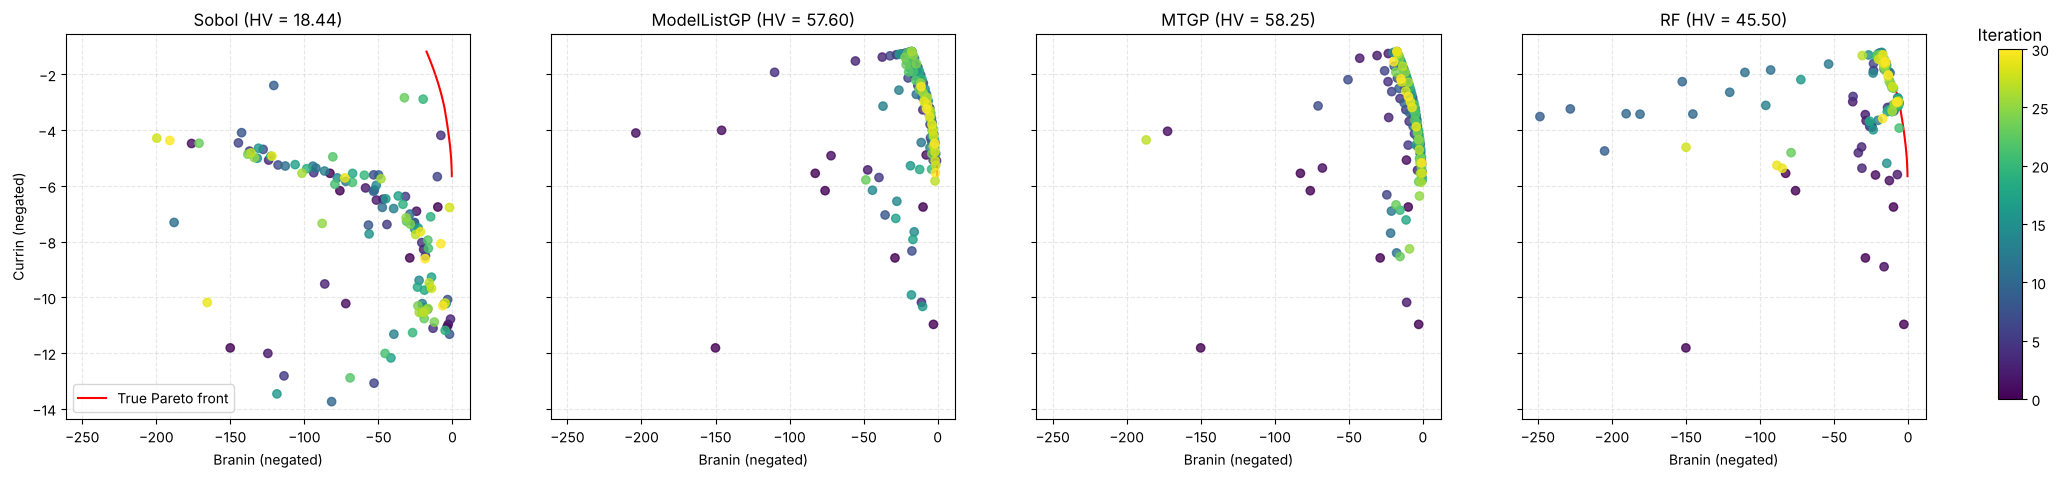

In [13]:
res = results[0]
batch_number = torch.cat([torch.zeros(N_INIT), torch.arange(1, N_BATCH + 1).repeat(BATCH_SIZE, 1).t().reshape(-1)]).numpy()
cm = plt.get_cmap("viridis")
norm = plt.Normalize(batch_number.min(), batch_number.max())

fig, axes = plt.subplots(1, len(METHODS), figsize=(24, 5), sharex=True, sharey=True)
for ax, m in zip(axes, METHODS):
    obj = res["data"][m]["obj_true"].cpu().numpy()
    ax.plot(true_pareto_Y[:, 0], true_pareto_Y[:, 1], c="red", linewidth=1.5, label="True Pareto front", zorder=1)
    ax.scatter(obj[:, 0], obj[:, 1], c=batch_number, cmap=cm, norm=norm, alpha=0.8, zorder=2)
    ax.set_title(f"{m} (HV = {res['hvs'][m][-1]:.2f})")
    ax.set_xlabel(objective_names[0])
    ax.grid(True, alpha=0.3, linestyle="--")
axes[0].set_ylabel(objective_names[1])
axes[0].legend(loc="lower left")
sm = ScalarMappable(norm=norm, cmap=cm)
sm.set_array([])
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.93, 0.15, 0.01, 0.7])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.ax.set_title("Iteration")
plt.show()

### 6.3 Points found in input space

The same evaluations in input space $[0,1]^2$, with the true Pareto set in red. This shows *where*
each surrogate sends the experiments. The GPs make smooth predictions, so they extrapolate between
observations. The RF predictions are axis-aligned and piecewise constant, which shapes where its
uncertainty is high and therefore where it explores.

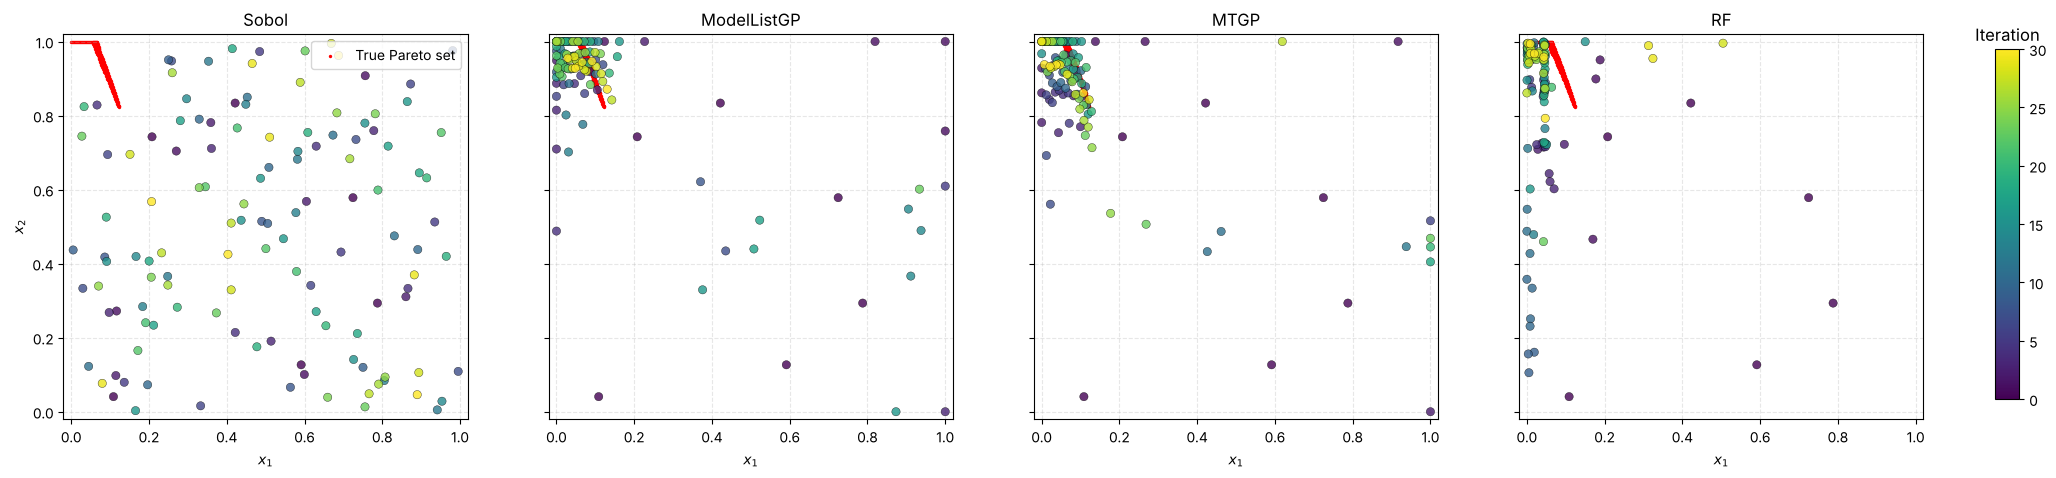

In [14]:
fig, axes = plt.subplots(1, len(METHODS), figsize=(24, 5), sharex=True, sharey=True)
for ax, m in zip(axes, METHODS):
    x = res["data"][m]["x"].cpu().numpy()
    ax.scatter(true_pareto_X[:, 0], true_pareto_X[:, 1], s=2, c="red", label="True Pareto set", zorder=1)
    ax.scatter(x[:, 0], x[:, 1], c=batch_number, cmap=cm, norm=norm, alpha=0.8, edgecolors="k", linewidths=0.3, zorder=2)
    ax.set_title(m)
    ax.set_xlabel("$x_1$")
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    ax.grid(True, alpha=0.3, linestyle="--")
axes[0].set_ylabel("$x_2$")
axes[0].legend(loc="upper right")
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.93, 0.15, 0.01, 0.7])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.ax.set_title("Iteration")
plt.show()

### 6.4 Surrogate accuracy on held-out points

Because BraninCurrin is synthetic, there is a check here that the experimental dataset could not
support: refit each surrogate on the **final** data it collected (first trial), then compare its
predictions with the *noise-free* objectives at 1000 fresh Sobol points across the whole domain.
The y-error bars show the model's $\pm 2\sigma$. For the GPs this is the posterior over the latent
function. For the RF it is tree variance plus the noise floor. Keep in mind that each model
is tested on data *it* chose: a model that concentrated its samples near the Pareto front can be less
accurate elsewhere, and that is not a failure.

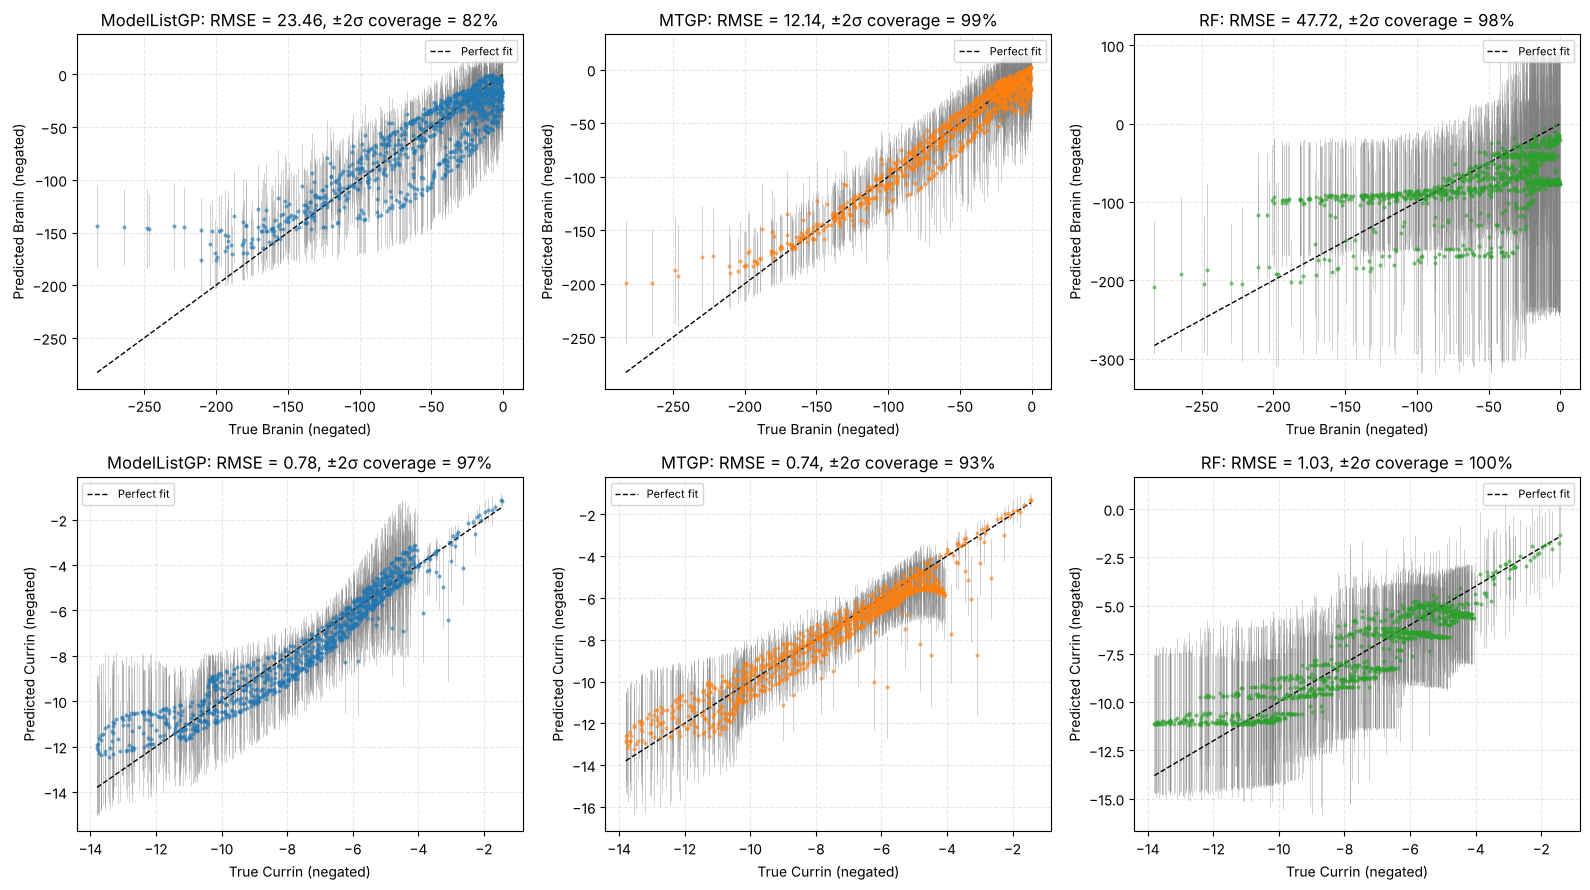

             n_train  RMSE Branin (negated)  ±2σ coverage Branin (negated)  RMSE Currin (negated)  ±2σ coverage Currin (negated)
model                                                                                                                           
ModelListGP      126                 23.457                          0.821                  0.778                          0.970
MTGP             126                 12.138                          0.994                  0.742                          0.934
RF               126                 47.718                          0.975                  1.030                          1.000


In [15]:
torch.manual_seed(RSEED)
test_x = draw_sobol_samples(bounds=problem.bounds, n=1000, q=1).squeeze(1)
test_obj_true = problem(test_x).cpu().numpy()

fig, axes = plt.subplots(2, len(MODEL_NAMES), figsize=(16, 9))
final_models, rmse_rows = {}, []
for j, m in enumerate(MODEL_NAMES):
    train_X, train_Y, train_Yvar, _, Y_mean, Y_std = prepare_training_data(res["data"][m]["x"], res["data"][m]["obj"])
    model = initialize_and_fit_model(m, train_X, train_Y, train_Yvar)
    final_models[m] = model
    with torch.no_grad():
        post = model.posterior(normalize(test_x, problem.bounds))
        mean = (post.mean * Y_std + Y_mean).cpu().numpy()
        std  = (post.variance.sqrt() * Y_std).cpu().numpy()

    row = {"model": m, "n_train": train_X.shape[0]}
    for i in range(2):
        ax = axes[i, j]
        rmse = np.sqrt(np.mean((mean[:, i] - test_obj_true[:, i]) ** 2))
        cover = np.mean(np.abs(mean[:, i] - test_obj_true[:, i]) <= 2 * std[:, i])
        row[f"RMSE {objective_names[i]}"] = rmse
        row[f"±2σ coverage {objective_names[i]}"] = cover
        ax.errorbar(test_obj_true[:, i], mean[:, i], yerr=2 * std[:, i], fmt="o", ms=2,
                    color=colors[m], ecolor="grey", elinewidth=0.5, alpha=0.5)
        lims = [test_obj_true[:, i].min(), test_obj_true[:, i].max()]
        ax.plot(lims, lims, "k--", linewidth=1, label="Perfect fit")
        ax.set(xlabel=f"True {objective_names[i]}", ylabel=f"Predicted {objective_names[i]}",
               title=f"{m}: RMSE = {rmse:.2f}, ±2σ coverage = {cover:.0%}")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3, linestyle="--")
    rmse_rows.append(row)
plt.tight_layout()
plt.show()

print(pd.DataFrame(rmse_rows).set_index("model").round(3).to_string())

### 6.5 What did the MTGP learn about the task correlation?

The learned inter-task covariance $K_f$ of the final MTGP (unconstrained `IndexKernel`), converted to a
correlation. For comparison, an MTGP with BoTorch's default `PositiveIndexKernel` is fitted to the same
data, and the empirical correlation of the two noise-free objectives over the whole domain (from the
dense grid) is shown as a reference.

In [16]:
def task_covariance(mtgp):
    '''Returns the learned inter-task covariance K_f and the implied task correlation.'''
    task_kernel = mtgp.covar_module.kernels[1]
    with torch.no_grad():
        Kf = task_kernel.covar_matrix.to_dense().cpu().numpy()   # full K_f, including the diagonal term
    return Kf, Kf[0, 1] / np.sqrt(Kf[0, 0] * Kf[1, 1])


# Same final data, BoTorch's default (non-negative) task kernel
train_X, train_Y, train_Yvar, _, _, _ = prepare_training_data(res["data"]["MTGP"]["x"], res["data"]["MTGP"]["obj"])
mtgp_positive = build_mtgp(train_X, train_Y, train_Yvar, rank=2, positive_task_corr=True)
fit_gpytorch_mll(ExactMarginalLogLikelihood(mtgp_positive.likelihood, mtgp_positive))

Kf, corr_index = task_covariance(final_models["MTGP"])
_, corr_positive = task_covariance(mtgp_positive)
corr_true = np.corrcoef(Y_grid.cpu().numpy().T)[0, 1]

print(f"Learned K_f, IndexKernel (inter-task covariance):\n{Kf.round(4)}\n")
print(f"Task correlation, IndexKernel (used in the BO loop): {corr_index:+.3f}")
print(f"Task correlation, PositiveIndexKernel (BoTorch default): {corr_positive:+.3f}")
print(f"Correlation of the true objectives (grid):           {corr_true:+.3f}")

Learned K_f, IndexKernel (inter-task covariance):
[[ 9.9124 -1.2016]
 [-1.2016  6.4112]]

Task correlation, IndexKernel (used in the BO loop): -0.151
Task correlation, PositiveIndexKernel (BoTorch default): +0.157
Correlation of the true objectives (grid):           -0.457


## 7. Discussion

### Hypervolume

| Method | HV after 40 obs. | Final HV (120 obs.) | % of max HV | Time / BO iteration |
|---|---|---|---|---|
| Sobol | 21.7 | 26.9 ± 4.5 | 45.3 % | – |
| ModelListGP | 53.1 | 57.70 ± 0.29 | 97.2 % | 15.9 s |
| MTGP | 55.0 | **58.20 ± 0.13** | **98.0 %** | 23.4 s |
| RF | 36.5 | 51.4 ± 1.7 | 86.7 % | 4.5 s |

*Means over 5 trials (± one standard error); max HV = 59.36. Observations are counted beyond the 6 initial points.*

- **Both GPs clearly beat the RF and the Sobol baseline.** After only 40 observations they are at ~89–93 %
  of the maximum hypervolume, and they keep refining the front for the rest of the run.
- **MTGP vs ModelListGP.** For the first ~30 observations the two are close, with the ModelListGP slightly
  ahead. After that the MTGP pulls ahead, and from roughly 40 observations on its log-HV-difference curve sits below the
  ModelListGP's, with non-overlapping error bands. The final gap is small in absolute terms
  (~0.5 HV, ~1 % of the max). One plausible reason is the held-out check in 6.4: the MTGP shares one
  input kernel across both objectives and is fitted on all $2n$ observations jointly, and on trial 1 its
  Branin model was about twice as accurate as the independent GP's (RMSE 12 vs 23). That is one trial's
  final model, not a controlled experiment, so treat it as an indication rather than a proof.
- **RF.** It does much better than Sobol (87 % vs 45 %), but it learns more slowly, and its progress slows sharply after
  about 55 observations. The scatter plots show why. In input space its late samples pile up along the
  left edge of the domain ($x_1 \lesssim 0.05$), next to the Pareto set but mostly not on its lower
  part. In objective space they cover the high-Currin end of the front well but rarely reach the end
  near Branin's minimum. Two properties of the model work against it:
  - its predictions are piecewise constant (the horizontal bands in the parity plots), so it cannot
    interpolate a smooth, curved front;
  - its uncertainty is a bootstrap proxy. The trees agree inside the sampled region, extrapolate
    with the same constant outside it, and the noise floor is the same everywhere, so qLogNEHVI gets
    little information about where hypervolume can still be gained.

  The gradient-free optimiser is not what holds it back: in 2D, 2048 Sobol candidates are a fine
  enough grid. The RF is by far the cheapest per iteration, but in a lab setting the cost of an
  experiment dwarfs a few seconds of compute, so sample efficiency is what counts.

### Surrogate accuracy & uncertainty (6.4)

The MTGP has the lowest held-out error on both objectives. The ModelListGP's Branin ±2σ band covers
only 82 % of the true values, so it is over-confident in regions it barely sampled. The RF's coverage of
98–100 % does **not** mean it is well calibrated. Its band includes the aleatoric noise floor (the GP
bands are for the noise-free latent function), and its errors are the largest of the three models.
Its bands are simply wide.

### Task correlation (6.5)

The two noise-free objectives are negatively correlated over the domain (−0.46). The unconstrained
`IndexKernel` recovers the right sign (−0.15). BoTorch's default `PositiveIndexKernel`, fitted to the
same data, reports +0.16 because it cannot go below zero. The magnitude is underestimated even by the
unconstrained kernel. A plausible reason is that BO data are concentrated around the Pareto set rather than
spread over the domain, while ICM summarises the relationship with a single global number. Note that the
BO loop does **not** compare the two task kernels, so this notebook does not measure how much the
swap contributes to the MTGP's performance. Rerun the loop with `positive_task_corr=True` to find out.

### Take-aways for the bioreactor problem

1. **The framework transfers unchanged.** The same three builders, the same known-noise handling
   (`train_Yvar`, scaled consistently with the outputs) and the same acquisition function close the
   loop on a problem where the answer is known.
2. **In this regime (few inputs, smooth objectives, small and noisy data), the GPs are the
   surrogates to drive BO with.** The RF is a useful cheap sanity check on predictions, but its
   uncertainty is not good enough to guide exploration.
3. **The MTGP's edge over independent GPs is real but modest here.** With ~20 experiments, as in the bioreactor
   dataset, it may not be detectable, so it is worth keeping both.
4. **Check the task kernel of your BoTorch version.** If `MultiTaskGP` uses `PositiveIndexKernel`, it cannot
   represent a trade-off (negative correlation) between `yield` and `biomass_productivity`.
   `build_mtgp(..., positive_task_corr=False)` lifts that restriction.

*Caveats:* a single 2-D benchmark, 5 trials, and hypervolume computed from noise-free values (which
are never available in the lab).